<center><img src="https://i.imgur.com/zRrFdsf.png" width="700"></center>





<a target="_blank" href="https://colab.research.google.com/github/CienciaDeDatosEspacial/spatial_autoCorr/blob/main/index.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Neighboorhood and Spatial Correlation.



## Getting ready


### Libraries needed

Let's verify:

In [1]:
!pip show pysal pandas geopandas

Name: pysal
Version: 25.7
Summary: Meta Package for PySAL - A library of spatial analysis functions
Home-page: 
Author: 
Author-email: Serge Rey <sjsrey@gmail.com>, Levi Wolf <levi.john.wolf@gmail.com>
License: BSD 3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: access, beautifulsoup4, esda, geopandas, giddy, inequality, libpysal, mapclassify, mgwr, momepy, numpy, packaging, pandas, platformdirs, pointpats, requests, scikit-learn, scipy, segregation, shapely, spaghetti, spglm, spint, splot, spopt, spreg, tobler
Required-by: 
---
Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution 

In [2]:
## needed in Colab
# !pip install pysal

### Data to use

Let me get two maps:

1. Here we have the USA map, at **state level**,  directly from census.gov, which has a good quality.

In [25]:
import geopandas as gpd

depas = "https://github.com/brunoleonardo0902/Ultima-Tarea-Individual/raw/main/PeruMaps.gpkg"
peru_depa = gpd.read_file(depas)

# checking data type,  crs, and confirming crs is projected
peru_depa.info(),peru_depa.crs.to_epsg(),peru_depa.crs.is_projected

/usr/local/lib/python3.13/dist-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'PeruMaps.gpkg': 'distritos' (default), 'good_geom'. Specify layer parameter to avoid this warning.
  result = read_func(


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1874 entries, 0 to 1873
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   DEPARTAMEN                1874 non-null   object  
 1   PROVINCIA                 1874 non-null   object  
 2   DISTRITO                  1874 non-null   object  
 3   Ubigeo                    1874 non-null   object  
 4   Poblacion                 1874 non-null   int64   
 5   Superficie                1874 non-null   float64 
 6   IDH2019                   1874 non-null   float64 
 7   Educ_sec_comp2019_pct     1874 non-null   float64 
 8   NBI2017_pct               1874 non-null   float64 
 9   Viv_sin_serv_hig2017_pct  1874 non-null   float64 
 10  geometry                  1874 non-null   geometry
dtypes: float64(5), geometry(1), int64(1), object(4)
memory usage: 161.2+ KB


(None, 4326, False)

Notice this map has basic information per state:

In [26]:
peru_depa.head()

,DEPARTAMEN,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
0,TACNA,TACNA,CORONEL GREGORIO ALBARRACIN LANCHIPA,230110,123662,187.74,0.578968,71.178389,15.8,0.8,"MULTIPOLYGON (((-70.17413 -18.12896, -70.17461..."
1,TACNA,TACNA,POCOLLAY,230108,22319,265.65,0.645954,75.825743,16.1,0.9,"MULTIPOLYGON (((-69.93475 -17.92557, -69.90467..."
2,TACNA,TACNA,CALANA,230103,3338,108.38,0.564102,77.829717,15.9,3.3,"MULTIPOLYGON (((-70.11604 -17.91106, -70.11457..."
3,TACNA,TACNA,TACNA,230101,80845,1877.78,0.696613,75.491958,7.4,0.6,"MULTIPOLYGON (((-70.3149 -17.94498, -70.30682 ..."
4,TACNA,TACNA,SAMA,230109,2679,1115.98,0.552622,70.500250,52.4,10.8,"MULTIPOLYGON (((-70.42497 -17.88934, -70.48022..."


Also, notice the current **unprojected** crs will plot this:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

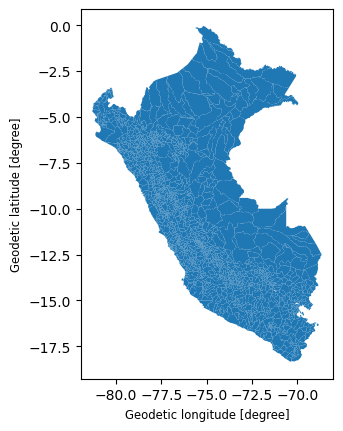

In [27]:
peru_depa.plot()

Let's reproject the crs:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

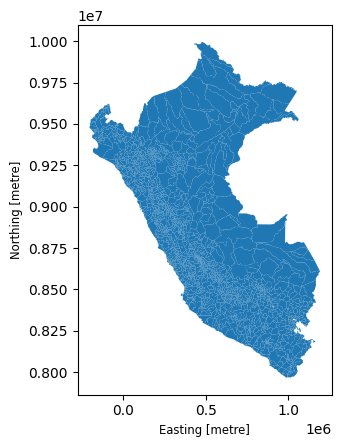

In [28]:
peru_depa=peru_depa.to_crs(32718)
peru_depa.plot()

Let's use the state name **as index**, that would help an easier identification of the places when we see most outputs (otherwise we will see just numerical indexes) :

In [29]:
print(peru_depa.columns)

Index(['DEPARTAMEN', 'PROVINCIA', 'DISTRITO', 'Ubigeo', 'Poblacion',
       'Superficie', 'IDH2019', 'Educ_sec_comp2019_pct', 'NBI2017_pct',
       'Viv_sin_serv_hig2017_pct', 'geometry'],
      dtype='object')


In [30]:
peru_depa.set_index('DEPARTAMEN', inplace=True)
peru_depa.head()

,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
DEPARTAMEN,,,,,,,,,,
TACNA,TACNA,CORONEL GREGORIO ALBARRACIN LANCHIPA,230110,123662,187.74,0.578968,71.178389,15.8,0.8,"MULTIPOLYGON (((1010996.85 7988839.86, 1010945..."
TACNA,TACNA,POCOLLAY,230108,22319,265.65,0.645954,75.825743,16.1,0.9,"MULTIPOLYGON (((1037016.18 8010729.01, 1040111..."
TACNA,TACNA,CALANA,230103,3338,108.38,0.564102,77.829717,15.9,3.3,"MULTIPOLYGON (((1017798.86 8012856.01, 1017955..."
TACNA,TACNA,TACNA,230101,80845,1877.78,0.696613,75.491958,7.4,0.6,"MULTIPOLYGON (((996581.5 8009636.68, 997417.24..."
TACNA,TACNA,SAMA,230109,2679,1115.98,0.552622,70.500250,52.4,10.8,"MULTIPOLYGON (((985046.53 8016100.15, 979024.7..."


Let's keep some states, which will help visuallly in most examples (mainly Part I,  and II):

In [31]:
someDepas=['UCAYALI','JUNIN','CUSCO']
sub_per=peru_depa[peru_depa.index.isin(someDepas)]
sub_per

,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
DEPARTAMEN,,,,,,,,,,
CUSCO,ESPINAR,CONDOROMA,080802,1431,513.36,0.422208,64.038906,48.4,28.3,"MULTIPOLYGON (((926234.03 8324455.76, 926306.8..."
CUSCO,ESPINAR,OCORURO,080804,1588,353.15,0.349129,63.638663,63.8,63.6,"MULTIPOLYGON (((906637.23 8347195.33, 906635.4..."
CUSCO,ESPINAR,SUYCKUTAMBO,080807,2781,652.13,0.319613,71.797466,42.9,11.2,"MULTIPOLYGON (((859759.79 8354924.35, 859935.5..."
CUSCO,ESPINAR,PALLPATA,080805,5593,815.56,0.394736,61.058717,40.6,34.7,"MULTIPOLYGON (((923276.3 8367888.79, 923579.9 ..."
CUSCO,ESPINAR,ESPINAR,080801,33970,747.78,0.553053,74.041288,19.0,6.4,"MULTIPOLYGON (((882728.82 8370825.84, 882825.1..."
...,...,...,...,...,...,...,...,...,...,...
UCAYALI,PADRE ABAD,NESHUYA,250304,8445,579.51,0.455819,45.883427,60.7,8.5,"MULTIPOLYGON (((498250.669 9066352.351, 498268..."
UCAYALI,PADRE ABAD,ALEXANDER VON HUMBOLDT,250305,6678,190.80,0.441129,43.119697,55.0,9.4,"MULTIPOLYGON (((497643.204 9033717.03, 497594...."
JUNIN,SATIPO,VIZCATAN DEL ENE,120609,3573,631.21,0.398199,53.437683,89.0,21.5,"MULTIPOLYGON (((579193 8665479, 579198 8665408..."


2. A map of Peru, at the **'distrito'** level (similar to municipality in the USA - not exactly the same). The map comes from an unoffical [website](https://www.geogpsperu.com/p/descargas.html). Some columns with **social data** have been added. This will be used at the end of this material.

In [33]:
peruDataLink="https://github.com/brunoleonardo0902/Ultima-Tarea-Individual/raw/main/PeruMaps.gpkg"
peru_distritos=gpd.read_file(peruDataLink,layer='distritos')

# some basic info
peru_distritos.info(),peru_distritos.crs.to_epsg(),peru_distritos.crs.is_projected

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1874 entries, 0 to 1873
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   DEPARTAMEN                1874 non-null   object  
 1   PROVINCIA                 1874 non-null   object  
 2   DISTRITO                  1874 non-null   object  
 3   Ubigeo                    1874 non-null   object  
 4   Poblacion                 1874 non-null   int64   
 5   Superficie                1874 non-null   float64 
 6   IDH2019                   1874 non-null   float64 
 7   Educ_sec_comp2019_pct     1874 non-null   float64 
 8   NBI2017_pct               1874 non-null   float64 
 9   Viv_sin_serv_hig2017_pct  1874 non-null   float64 
 10  geometry                  1874 non-null   geometry
dtypes: float64(5), geometry(1), int64(1), object(4)
memory usage: 161.2+ KB


(None, 4326, False)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

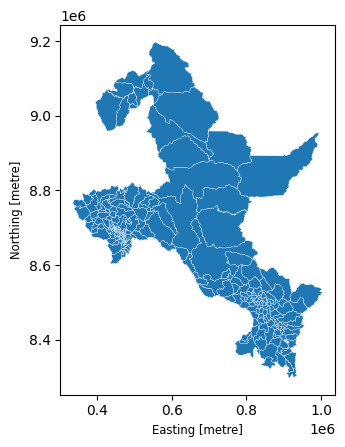

In [38]:

mis_depas = ['UCAYALI', 'JUNIN', 'CUSCO']

sub_peru = peru_distritos[peru_distritos['DEPARTAMEN'].isin(mis_depas)].copy()

sub_peru.plot(edgecolor='white', linewidth=0.2)

Let's reproject and plot:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

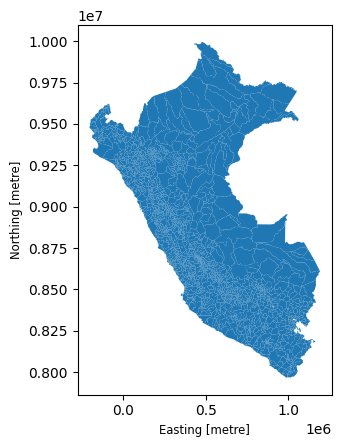

In [34]:
peru_distritos=peru_distritos.to_crs(32718)
peru_distritos.plot()

Besides the spatial units (DEPARTAMEN, PROVINCIA, DISTRITO, and Ubigeo - "Ubigeo" is a code ), you have:
 - **Poblacion**: Population (2017)
 - **Superficie**: Area               
 - **IDH2019**: Human Development Index for DISTRITO (2019)                   
 - **Educ_sec_comp2019_pct**: Share of Population that finished High-School (2019)     
 - **NBI2017_pct**: Share of Population with poverty at the household level aggregated by DISTRITO. This index ("Unsatisfied Basic Needs") uses observable living conditions rather than income alone (2017).
 - **Viv_sin_serv_hig2017_pct**: Share of housing units that have no sanitation infrastructure aggregated by  DISTRITO (2017)

The last two sections (III and IV) will need these **social data**.


Notice we should not use the 'distrito' name as index, because several of them are repeated:

In [39]:
sub_peru[sub_peru['DISTRITO'].duplicated()]

,DEPARTAMEN,PROVINCIA,DISTRITO,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
Ubigeo,,,,,,,,,,
120810,JUNIN,YAULI,YAULI,5113,424.16,0.704505,68.745549,22.6,7.1,"MULTIPOLYGON (((388660.95 8717251.03, 388793 8..."
120806,JUNIN,YAULI,PACCHA,1649,323.69,0.602010,73.058995,37.2,19.1,"MULTIPOLYGON (((399979.15 8747114.37, 400065.5..."


Let's use 'Ubigeo', although it is not the best solution

In [41]:
# of course
sub_peru[sub_peru.index.duplicated()]

,DEPARTAMEN,PROVINCIA,DISTRITO,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
Ubigeo,,,,,,,,,,


**NOTICE** both projections used above are equal-area ones, which are standard for distance computations in meters.

## I. Who is my neighbor?

In spatial analysis, the intuitive concept of a “neighbor” can be operationalized in multiple ways.

So far, we have identified neighbors using geometric operations such as buffering, spatial joins, and overlays.

In this session, let’s remember the distance matrix:


In [43]:
sub_peru.geometry.apply\
(lambda dist: sub_peru.distance(dist)/1000)

Ubigeo,080802,080804,080807,080805,080801,080808,080806,080803,080505,080503,...,250105,250106,250101,080912,080911,250304,250305,120609,080913,080914
Ubigeo,,,,,,,,,,,,,,,,,,,,,
080802,0.000000,0.000000,36.887013,0.000000,16.744277,39.044014,50.241237,39.297015,52.687497,55.501610,...,837.809771,852.280965,789.374283,317.544366,280.622748,818.351196,812.912704,445.843927,344.769431,358.953313
080804,0.000000,0.000000,26.451346,0.000000,0.000000,10.240909,20.246871,21.646085,31.459193,29.374836,...,808.276845,822.546365,760.839585,289.768459,253.563655,788.386188,782.905964,417.801249,317.006701,329.763703
080807,36.887013,26.451346,0.000000,29.124042,6.454172,24.291386,21.949309,0.000000,50.916790,35.168581,...,781.049253,793.880862,738.964229,249.362887,212.019220,757.920248,752.067048,377.506219,276.469999,306.895252
080805,0.000000,0.000000,29.124042,0.000000,0.000000,0.000000,8.863824,17.226312,9.322055,14.769202,...,796.788728,811.079513,747.401728,279.160842,243.122174,776.965372,771.497257,407.095828,306.387039,318.031113
080801,16.744277,0.000000,6.454172,0.000000,0.000000,0.000000,0.000000,0.000000,25.864056,12.095341,...,777.088408,791.021835,731.099973,256.642979,220.490968,756.462445,750.905746,384.670939,283.879738,299.326934
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
250304,818.351196,788.386188,757.920248,776.965372,756.462445,760.454566,747.875758,728.902527,743.680340,732.008146,...,33.253260,7.598720,33.309488,488.626697,505.206520,0.000000,0.000000,368.728623,471.433905,328.558963
250305,812.912704,782.905964,752.067048,771.497257,750.905746,754.980725,742.377875,723.277299,738.441700,726.694605,...,50.807581,40.101324,46.034543,481.852514,498.416419,0.000000,0.000000,360.990805,464.706590,323.288298
120609,445.843927,417.801249,377.506219,407.095828,384.670939,391.016922,378.185207,353.173016,382.590920,368.932315,...,405.651173,411.133932,390.500053,93.933662,109.886067,368.728623,360.990805,0.000000,78.063602,77.187517


You can see roughly the distances here:

(8297879.950011113, 9197797.250033246)

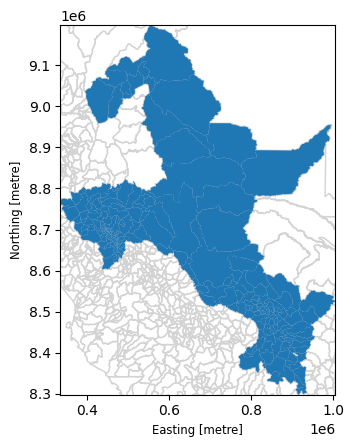

In [44]:
# Get the bounding box coordinates of sub_peru
minx, miny, maxx, maxy = sub_peru.total_bounds

base = peru_distritos.plot(facecolor='white', edgecolor='lightgrey')
sub_peru.plot(ax=base)

# Set the x and y limits of the plot to the bounding box
base.set_xlim(minx, maxx)
base.set_ylim(miny, maxy)

From this matrix and plot, you’ll notice that neighboring features have a distance of zero—this occurs when two polygons share a boundary (i.e., they are contiguous). This observation helps illustrate the different approaches to defining neighbors:

1. Binary Relationships:

* Contiguity: Two polygons are considered neighbors if they share any portion of their boundary—whether at a point, along a line segment, or more extensively. In the distance matrix, such pairs show a distance of zero, reflecting direct spatial adjacency.

    * Queen contiguity
    * Rook contiguity

* Proximity: This approches do not require contiguity.
    - Nearest Neighbors
    - Within influence zone

2. Continuous Relationships

* Contiguity: The relationship is graded by  the length of the shared boundary between contiguous neighbors.

* Proximity:
    - Nearest neighbors.
    - Within influence zone


Using matrices for this relationships—rather than raw geometries—is essential for the mathematical abstraction/representation and numerical computation required in upcoming spatial analytics techniques.

We will introduce some of PySAL (libpysal), which is designed to handle spatial relationship matrices and integrates seamlessly with GeoPandas. PySAL uses graph-based representations of these matrice, which  is not only more memory-efficient but also speeds up computation and simplifies visualization—especially for large or sparse spatial datasets.  A key concept in these graphs is the distinction between:

- Focal unit: the spatial feature (e.g., a state, county, or census tract) for which we are identifying neighbors.
- Neighbor(s): the other spatial units that are considered related to the focal unit based on a chosen criterion (e.g., contiguity, distance, or shared border length).

Let’s become familiar with the ```graph``` module in PySAL/libpysal, which provides a modern and flexible framework for constructing and working with spatial neighbor graphs.


In [45]:
from libpysal.graph import Graph

# also for reproducibility!
from numpy.random import seed
seed(42)

### I.1 Binary Contiguity

Take a look at the **queen** and **rook** relationship:

<center><img src="https://github.com/CienciaDeDatosEspacial/spatial_autoCorr/raw/main/rookQueen.png" width="700"></center>

From the image above:
- Your **rook** neighbor is whichever  shares a border with you (a borderline of at least two points). It is also known as the _Von Neumann_ neighbor.

- Your **queen** neighbor is whichever  shares a border or a corner with you (at least one point).It is also known as the _Moore_ neighbor.

Let's see how to get each set of neighbors

#### I.1.A. Rook

* The key idea: A focal polygon considers another polygon a neighbor if they share a common edge—that is, two or more connected points forming a line segment of positive length.
* The input: A GeoDataFrame (GDF) containing polygon geometries (e.g., states, counties, census tracts). Each row represents a spatial unit that can serve as a focal observation.
* The process: For each polygon (focal unit), the algorithm checks all other polygons to determine whether their boundaries intersect along a line segment (not just at a point).
* The output: A graph built from a binary adjacency matrix where each node represents a polygon (focal unit). An edge exists between two nodes only if they share a boundary segment. The corresponding adjacency matrix is binary. Isolates are possible.

Let's use **sub_us** GDF:

In [46]:
rook = Graph.build_contiguity(sub_peru, rook=True) # rook by default

Now let's check the ouput:

**a. adjacency**

In [47]:
rook.adjacency

focal   neighbor
080802  080804      1
        080805      1
080804  080802      1
        080805      1
        080801      1
                   ..
080913  080902      1
        080912      1
080914  080902      1
        120608      1
        250202      1
Name: weight, Length: 1322, dtype: int64

The previous results shows only the neighbors of the focals, to recreate a wide format:

In [48]:
import pandas as pd
pd.DataFrame(rook.adjacency).unstack()

weight                                                          \
neighbor 080802 080804 080807 080805 080801 080808 080806 080803 080505   
focal                                                                     
080802      NaN    1.0    NaN    1.0    NaN    NaN    NaN    NaN    NaN   
080804      1.0    NaN    NaN    1.0    1.0    NaN    NaN    NaN    NaN   
080807      NaN    NaN    NaN    NaN    NaN    NaN    NaN    1.0    NaN   
080805      1.0    1.0    NaN    NaN    1.0    1.0    NaN    NaN    NaN   
080801      NaN    1.0    NaN    1.0    NaN    1.0    1.0    1.0    NaN   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
250305      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
120609      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080913      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080914      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   

                 ...                                                          \
neighbor 080503  ... 250105 250106 250101 080912 080911 250304 250305 120609   
focal            ...                                                           
080802      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080804      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080807      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080805      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080801      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    1.0    NaN   
250305      NaN  ...    NaN    NaN    NaN    NaN    NaN    1.0    NaN    NaN   
120609      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
080913      NaN  ...    NaN    NaN    NaN    1.0    NaN    NaN    NaN    NaN   
080914      NaN  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   

                        
neighbor 080913 080914  
focal                   
080802      NaN    NaN  
080804      NaN    NaN  
080807      NaN    NaN  
080805      NaN    NaN  
080801      NaN    NaN  
...         ...    ...  
250304      NaN    NaN  
250305      NaN    NaN  
120609      NaN    NaN  
080913      NaN    NaN  
080914      NaN    NaN  

[253 rows x 253 columns]

We generally fill those missing values (not a neighbor) with zero.

In [49]:
rook_Matrix=pd.DataFrame(rook.adjacency).unstack().fillna(0)
rook_Matrix

weight                                                          \
neighbor 080802 080804 080807 080805 080801 080808 080806 080803 080505   
focal                                                                     
080802      0.0    1.0    0.0    1.0    0.0    0.0    0.0    0.0    0.0   
080804      1.0    0.0    0.0    1.0    1.0    0.0    0.0    0.0    0.0   
080807      0.0    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
080805      1.0    1.0    0.0    0.0    1.0    1.0    0.0    0.0    0.0   
080801      0.0    1.0    0.0    1.0    0.0    1.0    1.0    1.0    0.0   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
250305      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
120609      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080914      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                 ...                                                          \
neighbor 080503  ... 250105 250106 250101 080912 080911 250304 250305 120609   
focal            ...                                                           
080802      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080804      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080807      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080805      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080801      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
250305      0.0  ...    0.0    0.0    0.0    0.0    0.0    1.0    0.0    0.0   
120609      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0  ...    0.0    0.0    0.0    1.0    0.0    0.0    0.0    0.0   
080914      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                        
neighbor 080913 080914  
focal                   
080802      0.0    0.0  
080804      0.0    0.0  
080807      0.0    0.0  
080805      0.0    0.0  
080801      0.0    0.0  
...         ...    ...  
250304      0.0    0.0  
250305      0.0    0.0  
120609      0.0    0.0  
080913      0.0    0.0  
080914      0.0    0.0  

[253 rows x 253 columns]

SInce we are going to use several times, we may create a custom procedure:

In [50]:
#instead of
# pd.DataFrame(rook.adjacency).unstack().fillna(0)
toWideMatrix=lambda g:pd.DataFrame(g.adjacency).unstack().fillna(0)

Notice we created this wide matrix for pedagogical purposes. It is a bad idea if you have many columns and rows.

**b. adjacency graph**

As we have a `GRAPH`, we can identify these neighborhood relationships via edges:

In [51]:
##this will be used several times:
general_arguments=dict(gdf=sub_peru,node_kws=dict(color='red'), edge_kws=dict(alpha=0.4,color='blue'))
rook.explore(**general_arguments)

#### I.1.B. Queen

* The key idea: A focal polygon considers another polygon a neighbor if they share a common edge or a vertex (at least one point).
* The input: A GeoDataFrame (GDF) containing polygon geometries (e.g., states, counties, census tracts). Each row represents a spatial unit that can serve as a focal observation.
* The process: For each polygon (focal unit), the algorithm checks all other polygons to determine whether their boundaries intersect at any point or along a line segment.
* The output: A graph built from a binary adjacency matrix where each node represents a polygon (focal unit). An edge exists between two nodes only if they share a point or boundary segment. The corresponding adjacency matrix is binary. Isolates are possible.

Let's see what we get:

**a. adjacency matrix**

In [52]:
queen=Graph.build_contiguity(sub_peru,rook=False)

# applying our procedure:

queen_Matrix=toWideMatrix(queen)
queen_Matrix

weight                                                          \
neighbor 080802 080804 080807 080805 080801 080808 080806 080803 080505   
focal                                                                     
080802      0.0    1.0    0.0    1.0    0.0    0.0    0.0    0.0    0.0   
080804      1.0    0.0    0.0    1.0    1.0    0.0    0.0    0.0    0.0   
080807      0.0    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
080805      1.0    1.0    0.0    0.0    1.0    1.0    0.0    0.0    0.0   
080801      0.0    1.0    0.0    1.0    0.0    1.0    1.0    1.0    0.0   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
250305      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
120609      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080914      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                 ...                                                          \
neighbor 080503  ... 250105 250106 250101 080912 080911 250304 250305 120609   
focal            ...                                                           
080802      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080804      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080807      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080805      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080801      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
250305      0.0  ...    0.0    0.0    0.0    0.0    0.0    1.0    0.0    0.0   
120609      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0  ...    0.0    0.0    0.0    1.0    0.0    0.0    0.0    0.0   
080914      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                        
neighbor 080913 080914  
focal                   
080802      0.0    0.0  
080804      0.0    0.0  
080807      0.0    0.0  
080805      0.0    0.0  
080801      0.0    0.0  
...         ...    ...  
250304      0.0    0.0  
250305      0.0    0.0  
120609      0.0    0.0  
080913      0.0    0.0  
080914      0.0    0.0  

[253 rows x 253 columns]

**b. adjacency plot**

In [53]:
queen.explore(**general_arguments)


### I.2 Binary Proximity


#### I.2.A. Nearest Neighbors

* The key idea: A focal polygon considers another polygon a neighbor if that second polygon is among the K closest polygons to the focal polygon, where “closeness” is measured by the distance between their geometric centroids (or any other user-supplied distance metric).  
* The input: A GeoDataFrame (GDF) containing polygon geometries. Each row represents a spatial unit that can serve as a focal observation.  
* The process: For each polygon (focal unit), the algorithm (1) computes the distance between its centroid and every other centroid, (2) ranks these distances, and (3) flags the K smallest distances as neighbors. Ties can be broken by random selection, ID order, or by including all tied candidates.  
* The output: A graph built from a binary adjacency matrix where each node represents a polygon (focal unit). An edge exists between two nodes whenever one polygon is among the K nearest neighbors of the other. The corresponding adjacency matrix is binary and, by construction, typically asymmetric unless a symmetric constraint is explicitly enforced. No isolates in output.

If assume K is 3:

**a. adjacency matrix**

In [54]:
knn3 = Graph.build_knn(sub_peru.representative_point(), # GDF
                                 k=3) # desired k

knn3_Matrix=toWideMatrix(knn3)
knn3_Matrix

weight                                                          \
neighbor 080804 080805 080801 080802 080806 080803 080808 080503 080807   
focal                                                                     
080802      1.0    1.0    1.0    0.0    0.0    0.0    0.0    0.0    0.0   
080804      0.0    1.0    1.0    1.0    0.0    0.0    0.0    0.0    0.0   
080807      0.0    0.0    1.0    0.0    1.0    1.0    0.0    0.0    0.0   
080805      1.0    0.0    1.0    0.0    0.0    0.0    1.0    0.0    0.0   
080801      1.0    0.0    0.0    0.0    1.0    0.0    1.0    0.0    0.0   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
250305      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
120609      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080914      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                 ...                                                          \
neighbor 080502  ... 250107 250301 250304 250305 250302 250303 250102 250105   
focal            ...                                                           
080802      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080804      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080807      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080805      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080801      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0  ...    0.0    0.0    0.0    1.0    0.0    1.0    1.0    0.0   
250305      0.0  ...    0.0    0.0    1.0    0.0    1.0    0.0    1.0    0.0   
120609      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080914      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                        
neighbor 250106 080909  
focal                   
080802      0.0    0.0  
080804      0.0    0.0  
080807      0.0    0.0  
080805      0.0    0.0  
080801      0.0    0.0  
...         ...    ...  
250304      0.0    0.0  
250305      0.0    0.0  
120609      0.0    0.0  
080913      0.0    0.0  
080914      0.0    0.0  

[253 rows x 248 columns]

**b. adjacency plot**

In [55]:
knn3.explore(**general_arguments)

#### I.2.B Within zone of influence


* The key idea: A focal polygon considers another polygon a neighbor if the distance between them (usually centroid-to-centroid , or a pair of representative point) lies within a user-defined band.
* The input: A GeoDataFrame (GDF) containing polygon geometries for which a representative point is supplied. Each row represents a spatial unit that can serve as a focal observation, plus (optionally) an attribute column to use as a weight or ID.  
* The process: For each polygon (focal unit) the algorithm computes the distance to every other polygon and flags those whose distance falls inside the specified band.
* The output: A binary spatial graph (or adjacency structure) where each node represents a polygon. An edge exists between two nodes only if their mutual distance sits inside the chosen band. The corresponding adjacency matrix is binary and symmetric by construction. Isolates are possible.

Let's assume a 750 km distance band:

In [56]:
band750k_Bi=Graph.build_distance_band(sub_peru.representative_point(), threshold=750000)

band750k_Bi_Matrix=toWideMatrix(band750k_Bi)
band750k_Bi_Matrix

weight                                                          \
neighbor 080802 080804 080807 080805 080801 080808 080806 080803 080505   
focal                                                                     
080802      0.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
080804      1.0    0.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
080807      1.0    1.0    0.0    1.0    1.0    1.0    1.0    1.0    1.0   
080805      1.0    1.0    1.0    0.0    1.0    1.0    1.0    1.0    1.0   
080801      1.0    1.0    1.0    1.0    0.0    1.0    1.0    1.0    1.0   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
250305      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
120609      1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
080913      1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
080914      1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   

                 ...                                                          \
neighbor 080503  ... 250105 250106 250101 080912 080911 250304 250305 120609   
focal            ...                                                           
080802      1.0  ...    0.0    0.0    0.0    1.0    1.0    0.0    0.0    1.0   
080804      1.0  ...    0.0    0.0    0.0    1.0    1.0    0.0    0.0    1.0   
080807      1.0  ...    0.0    0.0    0.0    1.0    1.0    0.0    0.0    1.0   
080805      1.0  ...    0.0    0.0    0.0    1.0    1.0    0.0    0.0    1.0   
080801      1.0  ...    0.0    0.0    0.0    1.0    1.0    0.0    0.0    1.0   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0  ...    1.0    1.0    1.0    1.0    1.0    0.0    1.0    1.0   
250305      0.0  ...    1.0    1.0    1.0    1.0    1.0    1.0    0.0    1.0   
120609      1.0  ...    1.0    1.0    1.0    1.0    1.0    1.0    1.0    0.0   
080913      1.0  ...    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
080914      1.0  ...    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   

                        
neighbor 080913 080914  
focal                   
080802      1.0    1.0  
080804      1.0    1.0  
080807      1.0    1.0  
080805      1.0    1.0  
080801      1.0    1.0  
...         ...    ...  
250304      1.0    1.0  
250305      1.0    1.0  
120609      1.0    1.0  
080913      0.0    1.0  
080914      1.0    0.0  

[253 rows x 253 columns]

In [57]:
band750k_Bi.explore(**general_arguments)

### I.3 Continuos Proximity

#### I.3.A. Within zone of influence

* The key idea: A focal polygon considers another polygon a neighbor if the distance between them (usually centroid-to-centroid , or a pair of representative point) lies within a user-defined band.
* The input: A GeoDataFrame (GDF) containing polygon geometries for which a representative point is supplied. Each row represents a spatial unit that can serve as a focal observation, plus (optionally) an attribute column to use as a weight or ID.  
* The process: For each polygon (focal unit) the algorithm computes the distance to every other polygon and flags those whose distance falls inside the specified band.
* **The output**: a graph where each node has edges to all nodes ('neighbors') whose representative points lie within the radius. Edges are represented by a continuous adjacency matrix, the default values represent the inverse distance between the nodes in the edges. Isolates are possible

Here it is:

In [58]:
band2Mk_C=Graph.build_distance_band(sub_peru.representative_point(), threshold=2000000,binary=False)

band2Mk_C_Matrix=toWideMatrix(band2Mk_C)
band2Mk_C_Matrix


/usr/local/lib/python3.13/dist-packages/libpysal/graph/base.py:839: RuntimeWarning: divide by zero encountered in power
  kernel=lambda distances, alpha: np.power(distances, alpha),


weight                                                    \
neighbor    080802    080804    080807    080805    080801    080808   
focal                                                                  
080802    0.000000  0.000052  0.000015  0.000030  0.000022  0.000017   
080804    0.000052  0.000000  0.000018  0.000061  0.000036  0.000026   
080807    0.000015  0.000018  0.000000  0.000016  0.000029  0.000018   
080805    0.000030  0.000061  0.000016  0.000000  0.000035  0.000037   
080801    0.000022  0.000036  0.000029  0.000035  0.000000  0.000042   
...            ...       ...       ...       ...       ...       ...   
250304    0.000001  0.000001  0.000001  0.000001  0.000001  0.000001   
250305    0.000001  0.000001  0.000001  0.000001  0.000001  0.000001   
120609    0.000002  0.000002  0.000002  0.000002  0.000002  0.000002   
080913    0.000003  0.000003  0.000003  0.000003  0.000003  0.000003   
080914    0.000002  0.000002  0.000003  0.000002  0.000003  0.000003   

                                                  ...                      \
neighbor    080806    080803    080505    080503  ...    250105    250106   
focal                                             ...                       
080802    0.000015  0.000012  0.000013  0.000012  ...  0.000001  0.000001   
080804    0.000021  0.000015  0.000017  0.000016  ...  0.000001  0.000001   
080807    0.000021  0.000038  0.000013  0.000016  ...  0.000001  0.000001   
080805    0.000026  0.000015  0.000022  0.000019  ...  0.000001  0.000001   
080801    0.000040  0.000025  0.000020  0.000023  ...  0.000001  0.000001   
...            ...       ...       ...       ...  ...       ...       ...   
250304    0.000001  0.000001  0.000001  0.000001  ...  0.000016  0.000020   
250305    0.000001  0.000001  0.000001  0.000001  ...  0.000013  0.000014   
120609    0.000002  0.000003  0.000002  0.000002  ...  0.000002  0.000002   
080913    0.000003  0.000004  0.000003  0.000003  ...  0.000002  0.000002   
080914    0.000003  0.000003  0.000003  0.000003  ...  0.000002  0.000002   

                                                                      \
neighbor    250101    080912    080911    250304    250305    120609   
focal                                                                  
080802    0.000001  0.000003  0.000003  0.000001  0.000001  0.000002   
080804    0.000001  0.000003  0.000003  0.000001  0.000001  0.000002   
080807    0.000001  0.000004  0.000004  0.000001  0.000001  0.000002   
080805    0.000001  0.000003  0.000003  0.000001  0.000001  0.000002   
080801    0.000001  0.000003  0.000004  0.000001  0.000001  0.000002   
...            ...       ...       ...       ...       ...       ...   
250304    0.000008  0.000002  0.000002  0.000000  0.000045  0.000002   
250305    0.000007  0.000002  0.000002  0.000045  0.000000  0.000003   
120609    0.000002  0.000008  0.000006  0.000002  0.000003  0.000000   
080913    0.000002  0.000049  0.000020  0.000002  0.000002  0.000009   
080914    0.000002  0.000006  0.000006  0.000002  0.000003  0.000007   

                              
neighbor    080913    080914  
focal                         
080802    0.000003  0.000002  
080804    0.000003  0.000002  
080807    0.000003  0.000003  
080805    0.000003  0.000002  
080801    0.000003  0.000003  
...            ...       ...  
250304    0.000002  0.000002  
250305    0.000002  0.000003  
120609    0.000009  0.000007  
080913    0.000000  0.000007  
080914    0.000007  0.000000  

[253 rows x 253 columns]

The plot:

In [59]:
band2Mk_C.explore(**general_arguments)

Above, you do not see the continuous information present in the edges, for that, you may plot one of the states using **focal=**:

In [60]:
# pay attention to one district (ejemplo: '080101' es Cusco):
focal_args=dict(gdf=sub_peru,focal='080101',edge_kws=dict(column="weight",style_kwds=dict(weight=6)))
band2Mk_C.explore(**focal_args)


#### I.3.B. Kernel K-Nearest Neighbors (KNN)

* The key idea: Each polygon keeps only other  K closest polygons, but instead of a blunt 0 / 1 the tie is a gentle “friendliness” score that shrinks with distance.  
* The input: A GeoDataFrame of polygons + their representative points.  
* The process:  
  – Find the K nearest points.  
  – Turn distance into a Gaussian bell value (big when close, small when far).  

* The output: A weighted graph where every node has exactly K neighbours carrying continuous “soft” weights; no isolates, no huge clumps, just K tidy friendship levels per row.

Let's use K = 3 again:

In [61]:
kernel3 = Graph.build_kernel(sub_peru.representative_point(), k=3)

kernel3_Matrix=toWideMatrix(kernel3)
kernel3_Matrix

weight                                                    \
neighbor    080804    080805    080801    080802    080806    080803   
focal                                                                  
080802    0.396891  0.392903  0.387784  0.000000  0.000000  0.000000   
080804    0.000000  0.397493  0.394679  0.396891  0.000000  0.000000   
080807    0.000000  0.000000  0.392693  0.000000  0.386187  0.395221   
080805    0.397493  0.000000  0.394524  0.000000  0.000000  0.000000   
080801    0.394679  0.000000  0.000000  0.000000  0.395533  0.000000   
...            ...       ...       ...       ...       ...       ...   
250304    0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
250305    0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
120609    0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
080913    0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
080914    0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

                                         ...                          \
neighbor    080808 080503 080807 080502  ... 250107 250301    250304   
focal                                    ...                           
080802    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
080804    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
080807    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
080805    0.395011    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
080801    0.395876    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
...            ...    ...    ...    ...  ...    ...    ...       ...   
250304    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
250305    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.396288   
120609    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
080913    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   
080914    0.000000    0.0    0.0    0.0  ...    0.0    0.0  0.000000   

                                                                       
neighbor    250305    250302    250303    250102 250105 250106 080909  
focal                                                                  
080802    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
080804    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
080807    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
080805    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
080801    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
...            ...       ...       ...       ...    ...    ...    ...  
250304    0.396288  0.000000  0.394418  0.394875    0.0    0.0    0.0  
250305    0.000000  0.394916  0.000000  0.391459    0.0    0.0    0.0  
120609    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
080913    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  
080914    0.000000  0.000000  0.000000  0.000000    0.0    0.0    0.0  

[253 rows x 248 columns]

Notice we have bigger values that the continuous band-based result. Let's see the basic plot:

In [62]:

kernel3.explore(**general_arguments)

Focusing on one state:

In [63]:

kernel3.explore(**focal_args)

### I.4 Continuous Contiguity


* **The key idea**: A focal polygon treats another polygon as a neighbour only if the two share a common border.  
* **The input**: A GeoDataFrame of polygons; no extra points needed.  
* **The process**:  
  – Compute the exact length of every shared boundary segment.  

  
* **The output**: A weighted graph encoded in a sparse weights matrix; each non-zero entry is the **metres (or map-units) of shared border**, giving large, jagged polygons more influence over their neighbours than small, compact ones. Isolates are possible.

ERROR EN SUPERPOSICIONES
  

In [71]:
import geopandas as gpd
from shapely import make_valid, set_precision

# 1. Redondeamos vértices a 1 cm (0.01 m) para eliminar errores de punto flotante
geoms = [make_valid(set_precision(g, grid_size=0.01)) for g in sub_peru.geometry]

# 2. Restamos cualquier superposición en esa misma grilla exacta
for i in range(len(geoms)):
    for j in range(i + 1, len(geoms)):
        if geoms[i].intersects(geoms[j]):
            inter = geoms[i].intersection(geoms[j])
            if inter.area > 0:
                geoms[j] = make_valid(set_precision(geoms[j].difference(geoms[i]), grid_size=0.01))

sub_peru_clean = sub_peru.copy()
sub_peru_clean['geometry'] = gpd.GeoSeries(geoms, index=sub_peru.index)

# 3. Calculamos el perímetro compartido
perimeter = Graph.build_contiguity(sub_peru_clean, by_perimeter=True)

perimeter_Matrix = toWideMatrix(perimeter)
perimeter_Matrix

weight                                                   \
neighbor        080802        080804 080807        080805        080801   
focal                                                                     
080802        0.000000  26987.873683    0.0   9945.376153      0.000000   
080804    26987.873683      0.000000    0.0  46231.230738  17383.773596   
080807        0.000000      0.000000    0.0      0.000000      0.000000   
080805     9945.376153  46231.230738    0.0      0.000000  14735.523354   
080801        0.000000  17383.773596    0.0  14735.523354      0.000000   
...                ...           ...    ...           ...           ...   
250304        0.000000      0.000000    0.0      0.000000      0.000000   
250305        0.000000      0.000000    0.0      0.000000      0.000000   
120609        0.000000      0.000000    0.0      0.000000      0.000000   
080913        0.000000      0.000000    0.0      0.000000      0.000000   
080914        0.000000      0.000000    0.0      0.000000      0.000000   

                                                                  ...         \
neighbor        080808        080806        080803 080505 080503  ... 250105   
focal                                                             ...          
080802        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080804        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080807        0.000000      0.000000  54365.989501    0.0    0.0  ...    0.0   
080805    32505.320927      0.000000      0.000000    0.0    0.0  ...    0.0   
080801    21279.346050  14718.156884  37177.040053    0.0    0.0  ...    0.0   
...                ...           ...           ...    ...    ...  ...    ...   
250304        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
250305        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
120609        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080913        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080914        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   

                                                                         \
neighbor 250106 250101        080912 080911        250304        250305   
focal                                                                     
080802      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080804      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080807      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080805      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080801      0.0    0.0      0.000000    0.0      0.000000      0.000000   
...         ...    ...           ...    ...           ...           ...   
250304      0.0    0.0      0.000000    0.0      0.000000  31732.937622   
250305      0.0    0.0      0.000000    0.0  31732.937622      0.000000   
120609      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080913      0.0    0.0  21621.145551    0.0      0.000000      0.000000   
080914      0.0    0.0      0.000000    0.0      0.000000      0.000000   

                               
neighbor 120609 080913 080914  
focal                          
080802      0.0    0.0    0.0  
080804      0.0    0.0    0.0  
080807      0.0    0.0    0.0  
080805      0.0    0.0    0.0  
080801      0.0    0.0    0.0  
...         ...    ...    ...  
250304      0.0    0.0    0.0  
250305      0.0    0.0    0.0  
120609      0.0    0.0    0.0  
080913      0.0    0.0    0.0  
080914      0.0    0.0    0.0  

[253 rows x 253 columns]

The basic plot:

In [72]:

perimeter.explore(**general_arguments)

Focusing on one state:

In [73]:

perimeter.explore(**focal_args)

In summary:

| Technique | Pros | Cons | Typical use-case example |
|-----------|------|------|--------------------------|
| **Rook / Queen contiguity** | Simple, law- or admin-based, no distance parameter | Islands get 0 neighbours; ignores “near but not touching” units | State-to-state policy diffusion, local tax spill-overs |
| **K-NN (binary)** | Guarantees every unit has same #neighbours; no islands | Can link far-away units in sparse areas; ignores true borders | Comparative politics with same-size legislatures, small-N samples |
| **Distance band (binary)** | Hard cap on geographic reach; easy to interpret radius | Sparse → islands; dense → huge cliques; radius must be tuned | Housing-price spill-overs within 30 km commuting range |
| **Continuous distance-band** | Smooth weights, still respects max range | Same radius-tuning and island issues as binary band | Environmental exposure declining with distance, gravity models |
| **Kernel K-NN** | Fixed neighbour count, adaptive bandwidth, no islands | Far neighbours possible in deserts/oceans; parameter k to pick | Identifying neighbors that contribute to a smoothly decaying environmental hazard level.|
| **Perimeter-weighted contiguity** | Uses real boundary, good for irregular shapes | Needs clean topology; computation heavier | Ecological edge effects, river-basin pollution, crop pest spread |

## II. Neighborhoods as weights

Our matrices tell us which are neighbors, and some give us additional information related to the 'farness' of the identified neighbor. Let me compute the marginal values by row (sum):

In [74]:
allMx=[rook_Matrix.sum(axis=1),
       queen_Matrix.sum(axis=1),
       knn3_Matrix.sum(axis=1),
       band750k_Bi_Matrix.sum(axis=1),
       band2Mk_C_Matrix.sum(axis=1),
       kernel3_Matrix.sum(axis=1),
       perimeter_Matrix.sum(axis=1)]
pd.concat(allMx,axis=1)

,0,1,2,3,4,5,6
focal,,,,,,,
080802,2.0,2.0,3.0,242.0,0.000968,1.177578,36933.249836
080804,3.0,3.0,3.0,242.0,0.001119,1.189062,90602.878017
080807,1.0,1.0,3.0,242.0,0.001160,1.174102,54365.989501
080805,4.0,4.0,3.0,242.0,0.001170,1.187028,103417.451172
080801,5.0,5.0,3.0,242.0,0.001264,1.186087,105293.839936
...,...,...,...,...,...,...,...
250304,4.0,4.0,3.0,237.0,0.000776,1.185582,159448.076349
250305,3.0,3.0,3.0,242.0,0.000785,1.182664,58144.929955
120609,3.0,3.0,3.0,252.0,0.001375,1.144838,71404.841215


We know that no-neighbors have value zero in the matrix. Then, non-zero (binary or non-binary) values carries some weight .
However, they are currently not normalized (they do not add to 1 by row), which may bias further procedures as raw values may 'distort' mathematical modelling.

For example, this binary matrix is non-normalized:

In [75]:
queen_Matrix

weight                                                          \
neighbor 080802 080804 080807 080805 080801 080808 080806 080803 080505   
focal                                                                     
080802      0.0    1.0    0.0    1.0    0.0    0.0    0.0    0.0    0.0   
080804      1.0    0.0    0.0    1.0    1.0    0.0    0.0    0.0    0.0   
080807      0.0    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
080805      1.0    1.0    0.0    0.0    1.0    1.0    0.0    0.0    0.0   
080801      0.0    1.0    0.0    1.0    0.0    1.0    1.0    1.0    0.0   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
250305      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
120609      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080914      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                 ...                                                          \
neighbor 080503  ... 250105 250106 250101 080912 080911 250304 250305 120609   
focal            ...                                                           
080802      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080804      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080807      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080805      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080801      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
250304      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
250305      0.0  ...    0.0    0.0    0.0    0.0    0.0    1.0    0.0    0.0   
120609      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
080913      0.0  ...    0.0    0.0    0.0    1.0    0.0    0.0    0.0    0.0   
080914      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                        
neighbor 080913 080914  
focal                   
080802      0.0    0.0  
080804      0.0    0.0  
080807      0.0    0.0  
080805      0.0    0.0  
080801      0.0    0.0  
...         ...    ...  
250304      0.0    0.0  
250305      0.0    0.0  
120609      0.0    0.0  
080913      0.0    0.0  
080914      0.0    0.0  

[253 rows x 253 columns]

But this binary matrix is normalized (by **r**ows):

In [76]:
toWideMatrix(queen.transform("r"))

weight                                                         \
neighbor    080802 080804 080807    080805    080801 080808 080806 080803   
focal                                                                       
080802    0.000000   0.50    0.0  0.500000  0.000000   0.00    0.0    0.0   
080804    0.333333   0.00    0.0  0.333333  0.333333   0.00    0.0    0.0   
080807    0.000000   0.00    0.0  0.000000  0.000000   0.00    0.0    1.0   
080805    0.250000   0.25    0.0  0.000000  0.250000   0.25    0.0    0.0   
080801    0.000000   0.20    0.0  0.200000  0.000000   0.20    0.2    0.2   
...            ...    ...    ...       ...       ...    ...    ...    ...   
250304    0.000000   0.00    0.0  0.000000  0.000000   0.00    0.0    0.0   
250305    0.000000   0.00    0.0  0.000000  0.000000   0.00    0.0    0.0   
120609    0.000000   0.00    0.0  0.000000  0.000000   0.00    0.0    0.0   
080913    0.000000   0.00    0.0  0.000000  0.000000   0.00    0.0    0.0   
080914    0.000000   0.00    0.0  0.000000  0.000000   0.00    0.0    0.0   

                        ...                                                  \
neighbor 080505 080503  ... 250105 250106 250101    080912 080911    250304   
focal                   ...                                                   
080802      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
080804      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
080807      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
080805      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
080801      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
...         ...    ...  ...    ...    ...    ...       ...    ...       ...   
250304      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
250305      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.333333   
120609      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   
080913      0.0    0.0  ...    0.0    0.0    0.0  0.333333    0.0  0.000000   
080914      0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0  0.000000   

                                      
neighbor 250305 120609 080913 080914  
focal                                 
080802     0.00    0.0    0.0    0.0  
080804     0.00    0.0    0.0    0.0  
080807     0.00    0.0    0.0    0.0  
080805     0.00    0.0    0.0    0.0  
080801     0.00    0.0    0.0    0.0  
...         ...    ...    ...    ...  
250304     0.25    0.0    0.0    0.0  
250305     0.00    0.0    0.0    0.0  
120609     0.00    0.0    0.0    0.0  
080913     0.00    0.0    0.0    0.0  
080914     0.00    0.0    0.0    0.0  

[253 rows x 253 columns]

Another example, this binary matrix is non-normalized

In [77]:
perimeter_Matrix

weight                                                   \
neighbor        080802        080804 080807        080805        080801   
focal                                                                     
080802        0.000000  26987.873683    0.0   9945.376153      0.000000   
080804    26987.873683      0.000000    0.0  46231.230738  17383.773596   
080807        0.000000      0.000000    0.0      0.000000      0.000000   
080805     9945.376153  46231.230738    0.0      0.000000  14735.523354   
080801        0.000000  17383.773596    0.0  14735.523354      0.000000   
...                ...           ...    ...           ...           ...   
250304        0.000000      0.000000    0.0      0.000000      0.000000   
250305        0.000000      0.000000    0.0      0.000000      0.000000   
120609        0.000000      0.000000    0.0      0.000000      0.000000   
080913        0.000000      0.000000    0.0      0.000000      0.000000   
080914        0.000000      0.000000    0.0      0.000000      0.000000   

                                                                  ...         \
neighbor        080808        080806        080803 080505 080503  ... 250105   
focal                                                             ...          
080802        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080804        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080807        0.000000      0.000000  54365.989501    0.0    0.0  ...    0.0   
080805    32505.320927      0.000000      0.000000    0.0    0.0  ...    0.0   
080801    21279.346050  14718.156884  37177.040053    0.0    0.0  ...    0.0   
...                ...           ...           ...    ...    ...  ...    ...   
250304        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
250305        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
120609        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080913        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   
080914        0.000000      0.000000      0.000000    0.0    0.0  ...    0.0   

                                                                         \
neighbor 250106 250101        080912 080911        250304        250305   
focal                                                                     
080802      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080804      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080807      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080805      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080801      0.0    0.0      0.000000    0.0      0.000000      0.000000   
...         ...    ...           ...    ...           ...           ...   
250304      0.0    0.0      0.000000    0.0      0.000000  31732.937622   
250305      0.0    0.0      0.000000    0.0  31732.937622      0.000000   
120609      0.0    0.0      0.000000    0.0      0.000000      0.000000   
080913      0.0    0.0  21621.145551    0.0      0.000000      0.000000   
080914      0.0    0.0      0.000000    0.0      0.000000      0.000000   

                               
neighbor 120609 080913 080914  
focal                          
080802      0.0    0.0    0.0  
080804      0.0    0.0    0.0  
080807      0.0    0.0    0.0  
080805      0.0    0.0    0.0  
080801      0.0    0.0    0.0  
...         ...    ...    ...  
250304      0.0    0.0    0.0  
250305      0.0    0.0    0.0  
120609      0.0    0.0    0.0  
080913      0.0    0.0    0.0  
080914      0.0    0.0    0.0  

[253 rows x 253 columns]

We know:

In [78]:
pd.concat([perimeter_Matrix,perimeter_Matrix.sum(axis=1).rename("SUM")],axis=1)

,"(weight, 080802)","(weight, 080804)","(weight, 080807)","(weight, 080805)","(weight, 080801)","(weight, 080808)","(weight, 080806)","(weight, 080803)","(weight, 080505)","(weight, 080503)",...,"(weight, 250106)","(weight, 250101)","(weight, 080912)","(weight, 080911)","(weight, 250304)","(weight, 250305)","(weight, 120609)","(weight, 080913)","(weight, 080914)",SUM
focal,,,,,,,,,,,,,,,,,,,,,
080802,0.000000,26987.873683,0.0,9945.376153,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,36933.249836
080804,26987.873683,0.000000,0.0,46231.230738,17383.773596,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,90602.878017
080807,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,54365.989501,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,54365.989501
080805,9945.376153,46231.230738,0.0,0.000000,14735.523354,32505.320927,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,103417.451172
080801,0.000000,17383.773596,0.0,14735.523354,0.000000,21279.346050,14718.156884,37177.040053,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,105293.839936
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
250304,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,31732.937622,0.0,0.0,0.0,159448.076349
250305,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,31732.937622,0.000000,0.0,0.0,0.0,58144.929955
120609,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,71404.841215


Here it is normalized:

In [79]:
toWideMatrix(perimeter.transform("r"))

weight                                                           \
neighbor    080802    080804 080807    080805    080801    080808    080806   
focal                                                                         
080802    0.000000  0.730720    0.0  0.269280  0.000000  0.000000  0.000000   
080804    0.297870  0.000000    0.0  0.510262  0.191868  0.000000  0.000000   
080807    0.000000  0.000000    0.0  0.000000  0.000000  0.000000  0.000000   
080805    0.096167  0.447035    0.0  0.000000  0.142486  0.314312  0.000000   
080801    0.000000  0.165098    0.0  0.139947  0.000000  0.202095  0.139782   
...            ...       ...    ...       ...       ...       ...       ...   
250304    0.000000  0.000000    0.0  0.000000  0.000000  0.000000  0.000000   
250305    0.000000  0.000000    0.0  0.000000  0.000000  0.000000  0.000000   
120609    0.000000  0.000000    0.0  0.000000  0.000000  0.000000  0.000000   
080913    0.000000  0.000000    0.0  0.000000  0.000000  0.000000  0.000000   
080914    0.000000  0.000000    0.0  0.000000  0.000000  0.000000  0.000000   

                                  ...                                        \
neighbor    080803 080505 080503  ... 250105 250106 250101    080912 080911   
focal                             ...                                         
080802    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
080804    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
080807    1.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
080805    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
080801    0.353079    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
...            ...    ...    ...  ...    ...    ...    ...       ...    ...   
250304    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
250305    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
120609    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   
080913    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.372426    0.0   
080914    0.000000    0.0    0.0  ...    0.0    0.0    0.0  0.000000    0.0   

                                                   
neighbor    250304    250305 120609 080913 080914  
focal                                              
080802    0.000000  0.000000    0.0    0.0    0.0  
080804    0.000000  0.000000    0.0    0.0    0.0  
080807    0.000000  0.000000    0.0    0.0    0.0  
080805    0.000000  0.000000    0.0    0.0    0.0  
080801    0.000000  0.000000    0.0    0.0    0.0  
...            ...       ...    ...    ...    ...  
250304    0.000000  0.199017    0.0    0.0    0.0  
250305    0.545756  0.000000    0.0    0.0    0.0  
120609    0.000000  0.000000    0.0    0.0    0.0  
080913    0.000000  0.000000    0.0    0.0    0.0  
080914    0.000000  0.000000    0.0    0.0    0.0  

[253 rows x 253 columns]

Let's confirm:

In [80]:
Mtrans = toWideMatrix(perimeter.transform("r"))

# CORRECTED CODE
pd.concat([Mtrans, Mtrans.sum(axis=1).rename("SUM")], axis=1)

,"(weight, 080802)","(weight, 080804)","(weight, 080807)","(weight, 080805)","(weight, 080801)","(weight, 080808)","(weight, 080806)","(weight, 080803)","(weight, 080505)","(weight, 080503)",...,"(weight, 250106)","(weight, 250101)","(weight, 080912)","(weight, 080911)","(weight, 250304)","(weight, 250305)","(weight, 120609)","(weight, 080913)","(weight, 080914)",SUM
focal,,,,,,,,,,,,,,,,,,,,,
080802,0.000000,0.730720,0.0,0.269280,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0
080804,0.297870,0.000000,0.0,0.510262,0.191868,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0
080807,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0
080805,0.096167,0.447035,0.0,0.000000,0.142486,0.314312,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0
080801,0.000000,0.165098,0.0,0.139947,0.000000,0.202095,0.139782,0.353079,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
250304,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.199017,0.0,0.0,0.0,1.0
250305,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.545756,0.000000,0.0,0.0,0.0,1.0
120609,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0


These new row-standardized matrices will serve a greater purpose: the computing of **spatial lags**.

## III. How are my neighbors doing...?

The actual question should be related to a social variable, for example, poverty, mortality, education, etc.

For example, this is "how each distrito is doing" related to HS education (share of population that completed high school):

In [81]:
sub_peru.Educ_sec_comp2019_pct.describe()

,Educ_sec_comp2019_pct
count,253.000000
mean,60.539028
std,12.737034
min,12.942207
25%,52.486454
50%,61.376645
75%,70.021885
max,82.894658


See the choropleth (quantile bining):

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

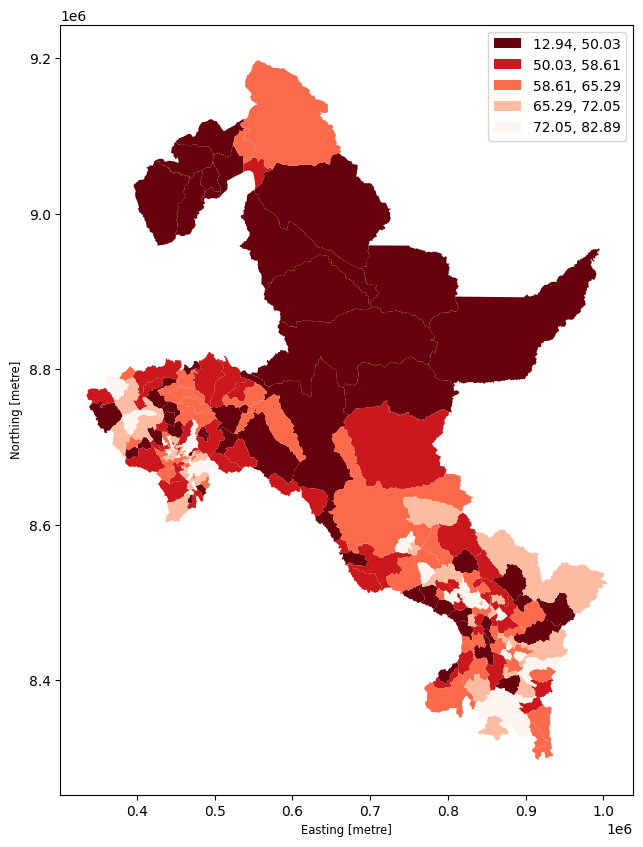

In [82]:
sub_peru.plot(
    "Educ_sec_comp2019_pct",
    scheme="quantiles",
    cmap="Reds_r",
    legend=True,figsize=(12, 10))

The title was asking about the situation of neighbors (the **neighbors** of each **focal** in my data). In this case, each focal has an education indicator (value), then, the average of the neighbors of each focal is a new value (new column) which we call **spatial lag** of that variable.

We do not have yet Peru's  neigborhood graph for the adjacency matrix. Let's try to get it:

In [102]:
peru_good = gpd.read_file(peruDataLink, layer='good_geom')

# Quitamos el prefijo 'PE' para tener el código estándar de 6 dígitos ('080101')
peru_good['Ubigeo'] = peru_good['ubigeo'].str.replace('PE', '', regex=False)

# Filtramos tus 3 departamentos usando el código de Ubigeo ('08' Cusco, '12' Junín, '25' Ucayali)
sub_good = peru_good[peru_good['Ubigeo'].str.startswith(('08', '12', '25'))].copy()
sub_good = sub_good.set_index('Ubigeo')

print("Cantidad de distritos filtrados:", len(sub_good))

Cantidad de distritos filtrados: 252


In [103]:
print(peru_good.columns.tolist())
peru_good.head(2)

['DEPARTAMENTO', 'PROVINCIA', 'DISTRITO', 'ubigeo', 'Poblacion', 'IDH2019', 'Educ_sec_comp2019_pct', 'NBI2017_pct', 'Viv_sin_serv_hig2017_pct', 'geometry', 'Ubigeo']


,DEPARTAMENTO,PROVINCIA,DISTRITO,ubigeo,Poblacion,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry,Ubigeo
0,Apurimac,ABANCAY,ABANCAY,PE030101,56871,0.600375,78.865450,15.8,2.9,"MULTIPOLYGON (((-72.93158 -13.55616, -72.9314 ...",030101
1,Ancash,BOLOGNESI,ABELARDO PARDO LEZAMETA,PE020502,1263,0.434687,50.434603,33.6,25.4,"MULTIPOLYGON (((-77.1474 -10.29675, -77.14643 ...",020502


Let's retry:

In [104]:
peru_perim=Graph.build_contiguity(sub_good,by_perimeter=True)

This time it worked!

Now, let's get the normalized matrix:

In [105]:
peru_perim=peru_perim.transform("r")

Then,  the spatial lag of the variable "Educ_sec_comp2019_pct" can be obtained like this:

In [106]:
ylag = peru_perim.lag(sub_good["Educ_sec_comp2019_pct"])

Let me add it to the GDF:

In [107]:
sub_good=sub_good.assign(Educ_sec_comp2019_pct_lagged=ylag)
sub_good.head()

,DEPARTAMENTO,PROVINCIA,DISTRITO,ubigeo,Poblacion,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry,Educ_sec_comp2019_pct_lagged
Ubigeo,,,,,,,,,,,
081002,Cusco,PARURO,ACCHA,PE081002,3839,0.300626,64.586647,28.6,11.1,"MULTIPOLYGON (((-71.80912 -13.92427, -71.80901...",47.770424
120202,Junin,CONCEPCION,ACO,PE120202,1592,0.377311,57.335334,27.3,21.4,"MULTIPOLYGON (((-75.39308 -11.92605, -75.39285...",62.979589
120702,Junin,TARMA,ACOBAMBA,PE120702,13586,0.419982,65.529955,25.7,15.1,"MULTIPOLYGON (((-75.62221 -11.31011, -75.62158...",60.018843
120402,Junin,JAUJA,ACOLLA,PE120402,7215,0.484661,62.978405,29.6,24.4,"MULTIPOLYGON (((-75.5491 -11.59829, -75.54718 ...",64.408507
080201,Cusco,ACOMAYO,ACOMAYO,PE080201,5627,0.348009,60.402557,30.9,12.4,"MULTIPOLYGON (((-71.63778 -13.83523, -71.6374 ...",53.109986


Let's plot HS share against its lag:

<Axes: xlabel='Educ_sec_comp2019_pct', ylabel='Educ_sec_comp2019_pct_lagged'>

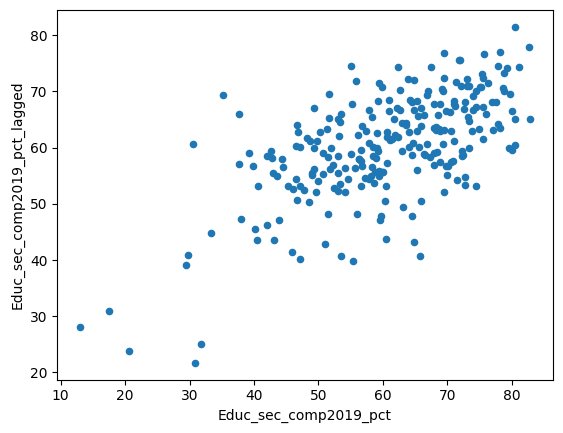

In [108]:
sub_good.plot.scatter("Educ_sec_comp2019_pct","Educ_sec_comp2019_pct_lagged")

## IV. Spatial autocorrelation

### IV. 1 Global

A correlation plot as the previous one should let us know if a variable is correlated with values of the neighbors (the lag), and if that were the case,  proximity is interfering statistical analysis, as the variable values are not independent.

The most well known measure to confirm that is the Moran's I index of global spatial correlation. Let's see the value we get:


In [109]:
import esda # from pysal

MoranGlobal_HS = esda.Moran(sub_good['Educ_sec_comp2019_pct'], peru_perim)

Once computed, you can retrieve its value and significance:

In [110]:
MoranGlobal_HS.I,MoranGlobal_HS.p_sim

(np.float64(0.47892309552312795), np.float64(0.001))

Moran’s I is interpreted like a Pearson r, but benchmarks are lower:

- |I| > 0.5 → strong, 0.2–0.5 → moderate, < 0.2 → weak.
- Sign indicates positive vs. negative spatial clustering.

Significance is assessed with a pseudo p-value from conditional randomisations of the data, because the theoretical null distribution is unknown for irregular spatial weights.

### IV. 2 Local

We can compute a Local Index of Spatial Association (LISA -local Moran) for each map polygon. That will help us find spatial clusters (spots) and spatial outliers:

- High-High (HH): values above average surrounded by values above average.These are also known as **hotSpot**s.
- Low-Low (LL): values below average surrounded by values below average. These are also known as **coldSpot**s.
- High-Low (HL): values above average surrounded by values below average.These are also known as **hotOutlier**s.
- Low-High (LH): values below average surrounded by values above average. These are also known as **coldOutlier**s.

It is also possible that no significant correlation is detected. Let's see those values:



a. Compute the LISAs:

In [111]:
lisa = esda.Moran_Local(sub_good['Educ_sec_comp2019_pct'], peru_perim)


The previous warning may be due to the presence of isolates, produced by perimeter algorithm:

In [112]:
peru_perim.isolates

Index([], dtype='object', name='focal')

These "islands" may create trouble. Should you keep using a _contiguity_ approach, you may consider fltering those out and recompute ``graph`` and ``lisa``:

In [113]:
islandCodes = peru_perim.isolates

peru_clean=sub_good.drop(index=islandCodes).copy()

peru_perim_clean=Graph.build_contiguity(peru_clean,by_perimeter=True).transform("r")
#
lisa = esda.Moran_Local(peru_clean['Educ_sec_comp2019_pct'], peru_perim_clean)



b. Plot the results (**fast way**)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

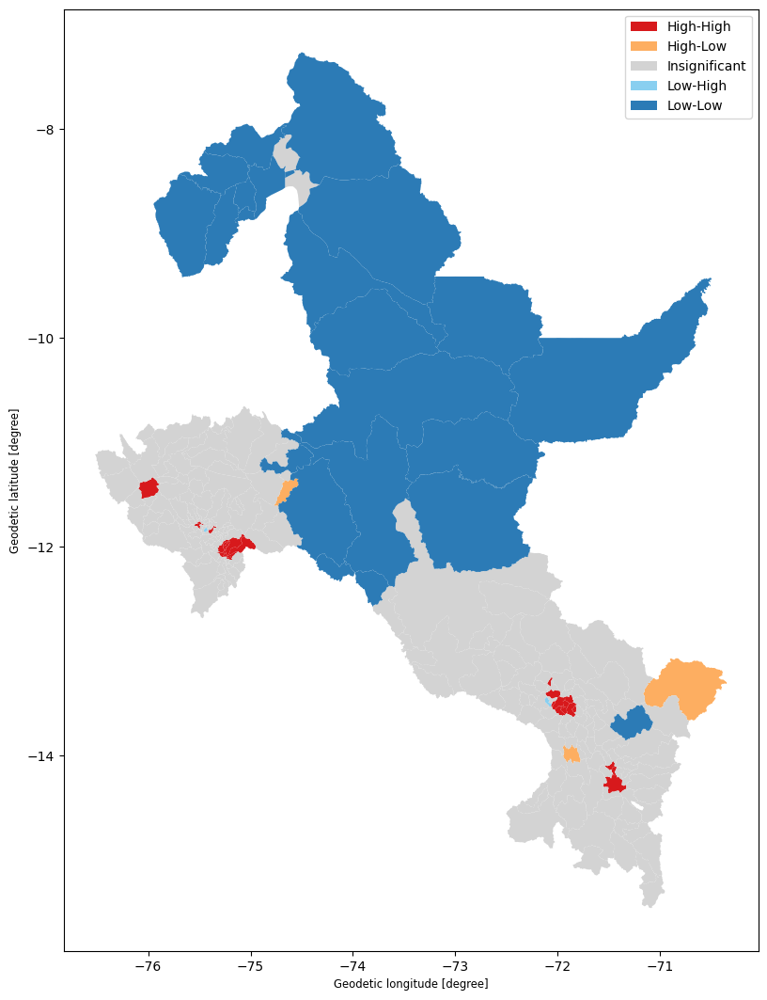

In [114]:
lisa.plot(peru_clean,crit_value=0.05,figsize=(10,13),legend=True)

#### IV. 2. 1 Analysis Local Spatial Correlation quadrants

You can not get the quadrant labels from the previous plot directly into the original GDF, thus complicating further analysis and exporting of those results.

First let's recover the labels into a new column:

In [115]:
# get the quadrants
peru_clean['HS_lisa'] = lisa.get_cluster_labels(crit_value=0.05)

In [116]:
# see the count
peru_clean['HS_lisa'].value_counts()

,count
HS_lisa,
Insignificant,197
High-High,28
Low-Low,22
High-Low,3
Low-High,2


Now, we can prepare a comparisson:

In [117]:
TheStats=["mean", "min", "max","var"]


# stats by the lisa cluster
grouped_stats = peru_clean.groupby('HS_lisa')['Educ_sec_comp2019_pct'].agg(TheStats)

# stats for the entire, ungrouped column
global_stats = peru_clean['Educ_sec_comp2019_pct'].agg(TheStats)

# Convert 'global_stats' (Series) to a DataFrame with an appropriate index name
global_stats_df = pd.DataFrame(global_stats).T
global_stats_df.index = ['Global/Total'] # simple but key

# Combine both
pd.concat([grouped_stats, global_stats_df])



,mean,min,max,var
High-High,73.530161,62.327807,82.659981,32.406221
High-Low,65.017069,64.586647,65.702088,0.359667
Insignificant,60.923351,30.492884,82.894658,113.586573
Low-High,57.159814,54.999469,59.320160,9.334183
Low-Low,40.283962,12.942207,60.420574,184.317666
Global/Total,60.541122,12.942207,82.894658,162.877253


From the results above, you may have several concerns and keep asking more questions:

- High-High clusters are concentrated areas of high percent of graduation from HighSchool. Is that expected in those areas? What has caused that? Has this been the same for a long time?

- Low-Low clusters are concentrated areas of low percent of graduation from HighSchool. What would it take to make a change in these areas? No doubt some kind of intervention is needed.

- High-Low clusters detect districts that outperform their neighbors. Can we leverage on those to improve the area? Are they in danger of worsening?

- Low-High clusters detect districts that are much worse than their neighbors, who are actually doing pretty well. Can we improve this place considering the surroundings need less intervention or not at all?

#### IV. 2. 2 Customizing Local Spatial Correlation quadrants

At this stage, we can rename the previous column to customize cluster labels and colors:

In [118]:
##knowing
peru_clean['HS_lisa'].unique()

array(['High-Low', 'Insignificant', 'Low-Low', 'High-High', 'Low-High'],
      dtype=object)

Keep in mind that the outliers may deserve more attention, so they may be at the top or bottom of the levels. You can add a number to achieve this purpose:

In [119]:
oldLabels=['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

# 3 will be at the middle
newLabels = ['3 no_pattern', '4 coldSpot','2 hotSpot','1 hotOutlier' , '5 coldOutlier']

labels = dict(zip(oldLabels, newLabels))

labels

{'Insignificant': '3 no_pattern',
 'Low-Low': '4 coldSpot',
 'High-High': '2 hotSpot',
 'High-Low': '1 hotOutlier',
 'Low-High': '5 coldOutlier'}

Just using this dictionary to rename the column:

In [120]:

peru_clean.replace({'HS_lisa':labels},inplace=True)

## see the count
peru_clean['HS_lisa'].value_counts().sort_index()

,count
HS_lisa,
1 hotOutlier,3
2 hotSpot,28
3 no_pattern,197
4 coldSpot,22
5 coldOutlier,2


Finally, used that order to assign diverging color-blind safe palette:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

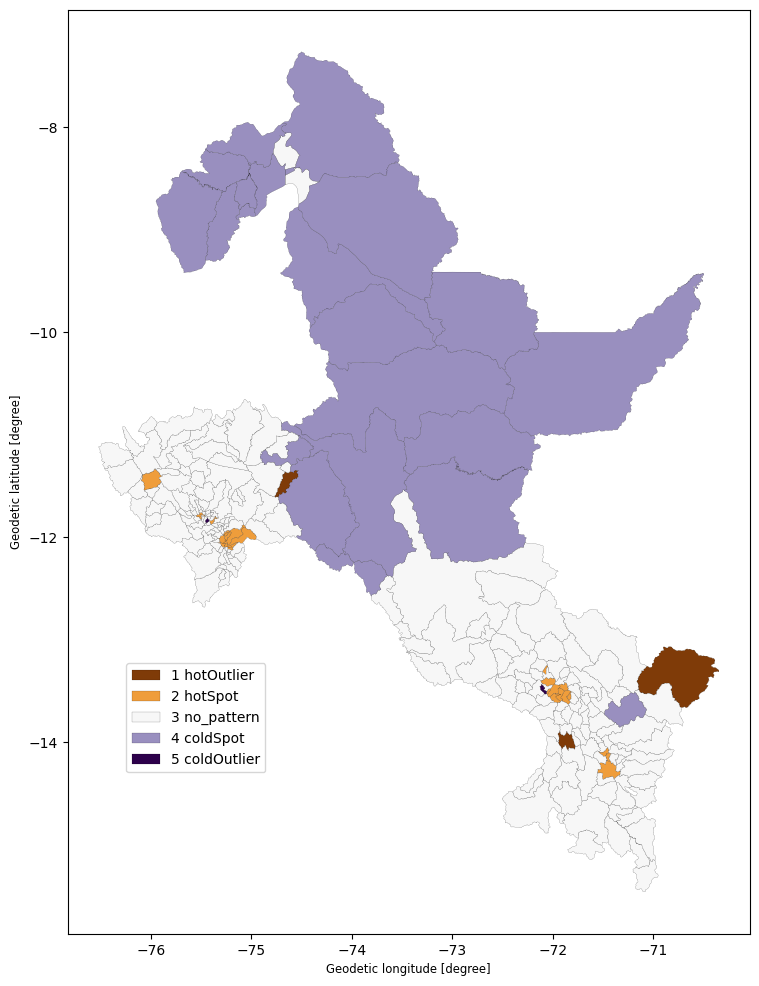

In [121]:
##custom colors- respect the previous order

import matplotlib.pyplot as plt
myColMap = plt.get_cmap('PuOr', 5)


##plot the map

peru_clean.plot(column='HS_lisa',
                categorical=True,
                cmap=myColMap,
                linewidth=0.1,
                edgecolor='k',
                legend=True,
                legend_kwds={'bbox_to_anchor': (0.3, 0.3)},
                figsize=(12,12))